In [2]:
!pip install scikit-learn imbalanced-learn xgboost shap lime matplotlib seaborn scipy joblib



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import shap
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr, kendalltau
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True); os.makedirs("outputs", exist_ok=True)
sns.set_theme(style="whitegrid")

C:\Users\prabh\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
csv_name = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not os.path.exists(csv_name):
    import kagglehub, shutil
    path = kagglehub.dataset_download("blastchar/telco-customer-churn")
    shutil.copy(os.path.join(path, csv_name), csv_name)
df = pd.read_csv(csv_name)
print(df.shape)

(7043, 21)


In [5]:
#cleaning
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing = df[df["TotalCharges"].isna()]
print(len(missing), "blank rows; all tenure 0:", bool((missing["tenure"] == 0).all()))
df.loc[df["TotalCharges"].isna(), "TotalCharges"] = 0.0

customer_ids = df["customerID"].copy()
df = df.drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)

print("Duplicates:", df.duplicated().sum(), "| Missing:", int(df.isna().sum().sum()))
print(f"Churn rate: {df['Churn'].mean():.1%}")

11 blank rows; all tenure 0: True
Duplicates: 22 | Missing: 0
Churn rate: 26.5%


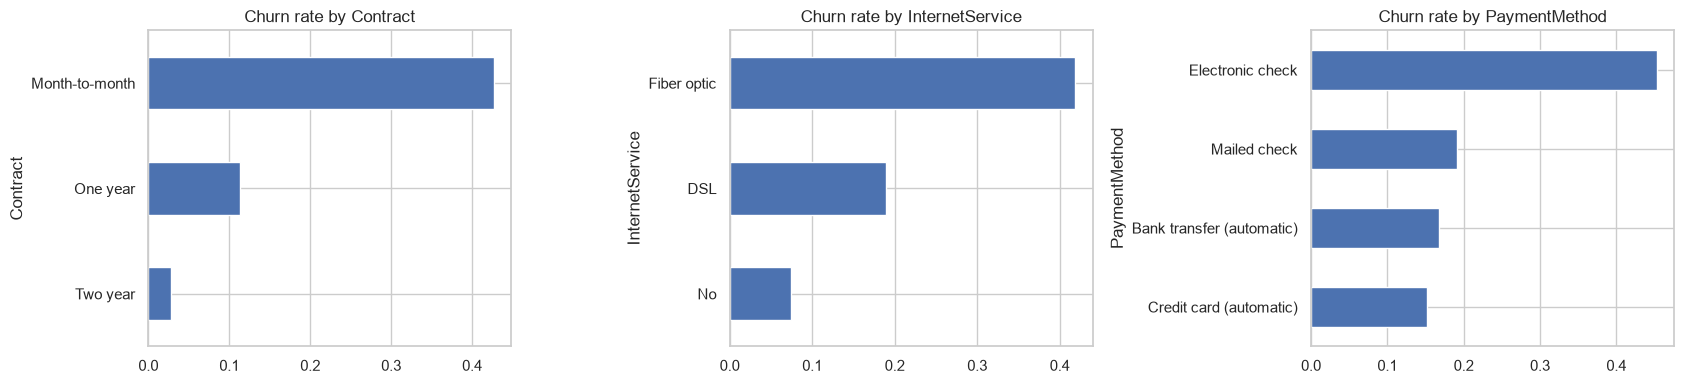

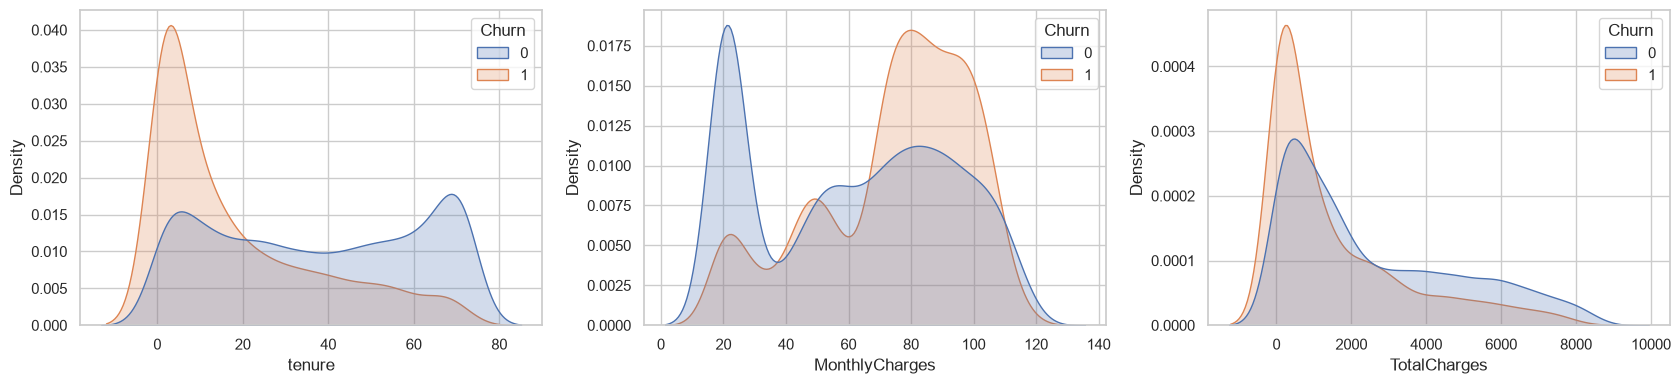

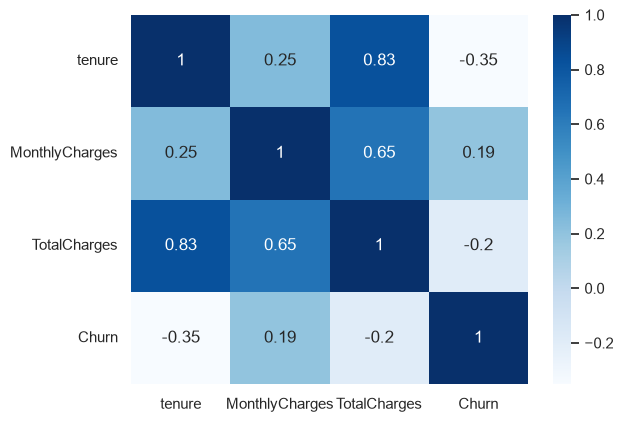

In [6]:
#EDA
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, col in zip(ax, ["Contract", "InternetService", "PaymentMethod"]):
    df.groupby(col)["Churn"].mean().sort_values().plot.barh(ax=a)
    a.set_title(f"Churn rate by {col}")
plt.tight_layout(); plt.savefig("figures/eda_categories.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, col in zip(ax, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.kdeplot(data=df, x=col, hue="Churn", common_norm=False, fill=True, ax=a)
plt.tight_layout(); plt.savefig("figures/eda_numeric.png", dpi=150); plt.show()

sns.heatmap(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].corr(), annot=True, cmap="Blues")
plt.savefig("figures/eda_corr.png", dpi=150); plt.show()

In [7]:
#split and preprocessing
X = df.drop(columns="Churn"); y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
], sparse_threshold=0)

In [8]:
#SMOTE vs class-weighting
neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())

def build(model_name, strategy):
    cw = "balanced" if strategy == "class_weight" else None
    if model_name == "LogReg":
        model = LogisticRegression(max_iter=2000, class_weight=cw, random_state=RANDOM_STATE)
    elif model_name == "RandomForest":
        model = RandomForestClassifier(n_estimators=300, class_weight=cw, n_jobs=-1, random_state=RANDOM_STATE)
    else:
        model = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                              scale_pos_weight=(neg / pos if strategy == "class_weight" else 1.0),
                              eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)
    steps = [("prep", preprocess)]
    if strategy == "smote":
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return ImbPipeline(steps)

MODELS = ["LogReg", "RandomForest", "XGBoost"]
STRATEGIES = ["none", "class_weight", "smote"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["precision", "recall", "f1", "roc_auc"]

rows = []
for name in MODELS:
    for strat in STRATEGIES:
        res = cross_validate(build(name, strat), X_train, y_train, cv=cv, scoring=scoring)
        rows.append({"model": name, "strategy": strat,
                     **{s: round(res[f"test_{s}"].mean(), 3) for s in scoring}})
comparison = pd.DataFrame(rows)
comparison.to_csv("outputs/imbalance_comparison.csv", index=False)
print(comparison)

strategy_scores = comparison.groupby("strategy")[scoring].mean().round(3)
print(strategy_scores)
best_strategy = strategy_scores["f1"].idxmax()
print("Carried forward:", best_strategy)

          model      strategy  precision  recall     f1  roc_auc
0        LogReg          none      0.653   0.544  0.593    0.846
1        LogReg  class_weight      0.518   0.803  0.629    0.846
2        LogReg         smote      0.526   0.791  0.632    0.845
3  RandomForest          none      0.630   0.480  0.544    0.822
4  RandomForest  class_weight      0.569   0.654  0.609    0.824
5  RandomForest         smote      0.587   0.571  0.579    0.821
6       XGBoost          none      0.649   0.515  0.574    0.845
7       XGBoost  class_weight      0.533   0.773  0.631    0.844
8       XGBoost         smote      0.613   0.631  0.622    0.843
              precision  recall     f1  roc_auc
strategy                                       
class_weight      0.540   0.743  0.623    0.838
none              0.644   0.513  0.570    0.838
smote             0.575   0.664  0.611    0.836
Carried forward: class_weight


In [9]:
#Tune models
grids = {
    "LogReg": {"model__C": [0.01, 0.1, 1, 10]},
    "RandomForest": {"model__n_estimators": [200, 400], "model__max_depth": [None, 8, 12],
                     "model__min_samples_leaf": [1, 3, 5]},
    "XGBoost": {"model__n_estimators": [200, 400], "model__max_depth": [3, 4, 6],
                "model__learning_rate": [0.03, 0.05, 0.1], "model__subsample": [0.8, 1.0]},
}
tuned = {}
for name in MODELS:
    search = RandomizedSearchCV(build(name, best_strategy), grids[name], n_iter=8,
                                scoring="f1", cv=cv, random_state=RANDOM_STATE)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    print(name, search.best_params_, round(search.best_score_, 3))

LogReg {'model__C': 1} 0.629
RandomForest {'model__n_estimators': 200, 'model__min_samples_leaf': 3, 'model__max_depth': 8} 0.634
XGBoost {'model__subsample': 0.8, 'model__n_estimators': 200, 'model__max_depth': 3, 'model__learning_rate': 0.05} 0.633


          model  precision  recall     f1  roc_auc
0        LogReg      0.504   0.783  0.614    0.841
1  RandomForest      0.524   0.797  0.632    0.843
2       XGBoost      0.519   0.797  0.629    0.845


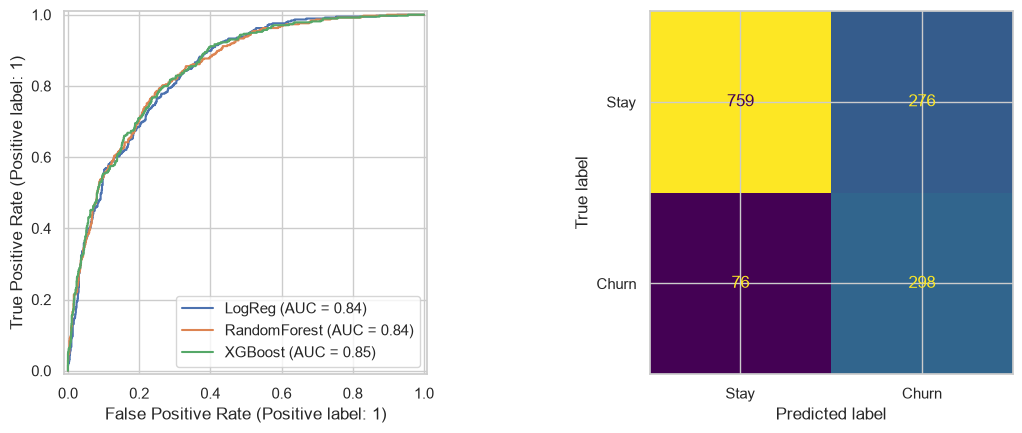

Best model: XGBoost


In [10]:
#Evaluate on the test set
rows = []
for name, pipe in tuned.items():
    pred = pipe.predict(X_test); proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({"model": name,
                 "precision": round(precision_score(y_test, pred), 3),
                 "recall": round(recall_score(y_test, pred), 3),
                 "f1": round(f1_score(y_test, pred), 3),
                 "roc_auc": round(roc_auc_score(y_test, proba), 3)})
test_metrics = pd.DataFrame(rows)
test_metrics.to_csv("outputs/test_metrics.csv", index=False)
print(test_metrics)

best_model_name = test_metrics.sort_values("roc_auc", ascending=False).iloc[0]["model"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, pipe in tuned.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax[0])
ConfusionMatrixDisplay.from_estimator(tuned[best_model_name], X_test, y_test,
                                      display_labels=["Stay", "Churn"], ax=ax[1], colorbar=False)
plt.tight_layout(); plt.savefig("figures/evaluation.png", dpi=150); plt.show()
print("Best model:", best_model_name)